# 005. Nonradiative Transition Rates Using the Non-Adiabatic Coupling Vector

### VV0 center in 4H-SiC (*kk* configuration) simulated at the PBE level on a 5x5x2 cell with 398 atoms

The notebook is organized into two parts:
   1. Compute the electron-phonon coupling matrix element using the NAC vector obtained from TDDFT calculations.
   2. Compute the nonradiative rate.


In [1]:
%matplotlib widget

import os, sys
path = os.getcwd()
os.chdir(path)
sys.path.append('/home/svillani/Programs/pypl/pypl/')
import hr_nonrad_solver

import numpy as np
from scipy import constants
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})

blue = '#4285F4'
red = '#DB4437'
deep_violet = '#9D80B8'
vibrant_purple = '#D391C2'
soft_coral = '#F3B1BA'
ocean_blue = '#81BFD6'
goldenrod_yellow = '#EBD68F'
emerald_green = '#02A650'

eV = constants.eV
amu = constants.physical_constants['atomic mass constant'][0]
hbar = constants.hbar
ry2eV = 13.6057039763
bohr2ang = 0.529177249

## 1. Compute the electron-phonon coupling matrix element using the NAC vectors obtained from TDDFT calculations.

In the spin-flip TDDFT calculation, the ${}^1\!A_1$ state is state 4, and the ${}^1\!E$ states are states 2 and 3. At the optimized geometry of the ${}^1\!A_1$ state, the ${}^1\!E$ states are doubly degenerate. We will compute the electron-phonon coupling matrix elements between state 4 and both state 2 and state 3.

In the NOT spin-flip TDDFT calculation, the ${}^3\!A_2$ state is the ground state, and the ${}^3\!E$ states are states 2 and 1. At the optimized geometry of the ${}^3\!A_2$ state, the ${}^3\!E$ states are doubly degenerate. At the optimized geometry of the ${}^3\!E$ state, the degeneracy is lifted. We will compute the electron-phonon coupling matrix elements between the ground state and both state 1 and state 2.

In [2]:
from hr_nonrad_solver import hr_nonrad_solver
from utils import *

# phonons are computed at the pbe level of theory
state_1A1_phonon_file = 'PBE/1A1_ph_mesh.hdf5'
# =========================================================================================
# PBE results
nac_1A1_1E_state2_file_pbe = 'PBE/1A1/west.wbse.save/wbse.json'
nac_1A1_1E_state3_file_pbe = 'PBE/1A1/west.wbse.save/wbse_1.json'
state_1A1_pwscf_file_pbe = 'PBE/1A1/pwscf.xml'
# 
forces_1E_state2_file_pbe = 'PBE/1A1/west.wbse.save/wbse.json'
forces_1E_state3_file_pbe = 'PBE/1A1/west.wbse.save/wbse_1.json'
#
# Rydberg to eV
energy_1E_state2_pbe = 0.030397069328569407 * ry2eV # at 1A1 relax geo
energy_1E_state3_pbe = 0.03052390546464423 * ry2eV # at 1A1 relax geo
energy_1A1_pbe = 0.07111570617603402 * ry2eV # at 1A1 relax geo
# =========================================================================================
# DDH results
nac_1A1_1E_state2_file_ddh = 'DDH/1A1/west.wbse.save/wbse.json'
state_1A1_pwscf_file_ddh = 'DDH/1A1/pwscf.xml'

forces_1E_state2_file_ddh = 'DDH/1A1/west.wbse.save/wbse.json'

# Rydberg to eV
energy_1E_state2_ddh = 0.04083727153217377 * ry2eV # at 1A1 relax geo
energy_1A1_ddh = 0.11143638608178978 * ry2eV # at 1A1 relax geo

# Adiabatic transition energies (meV)
adiabatic_energy_1A1_1E_pbe = 0.633 * 1000 # mev, theoretical TDDFT-PBE value from JCTC 2023 (Yu Jin et al.)
adiabatic_energy_1A1_1E_ddh = 1.132 * 1000 # mev, theoretical TDDFT-DDH value from JCTC 2023 (Yu Jin et al.)

In [3]:
def parse_forces_from_wbse_json(filename):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    forces = np.array(data['output']['forces']['forces_corrected']).reshape(-1, 3)
    # Ry/bohr to eV/Angstrom
    forces *= (ry2eV / bohr2ang)
    return forces

def parse_nac_from_wbse_json(filename, nac_type):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    nac = np.array(data['output']['nac_vec'][nac_type]).reshape(-1, 3)
    # 1/bohr to 1/Angstrom
    nac /= bohr2ang
    return nac

We can parse the NAC vector from the WEST output file

PBE results first

In [4]:
nac_vec_1A1_1E_state2_pbe = parse_nac_from_wbse_json(nac_1A1_1E_state2_file_pbe,'eenac_corrected')
print(nac_vec_1A1_1E_state2_pbe.shape)
print(nac_vec_1A1_1E_state2_pbe[-5:])
print()

nac_vec_1A1_1E_state3_pbe = parse_nac_from_wbse_json(nac_1A1_1E_state3_file_pbe,'eenac_corrected')
print(nac_vec_1A1_1E_state3_pbe.shape)
print(nac_vec_1A1_1E_state3_pbe[-5:])
print()

(398, 3)
[[ 0.05398967  0.00615876  0.06257621]
 [-0.00458792  0.00807303 -0.00418086]
 [ 0.04240155  0.0696759   0.16125082]
 [ 0.00381349 -0.00513059 -0.00272704]
 [ 0.05958998  0.02073027  0.10840643]]

(398, 3)
[[ 0.04245893 -0.05096277  0.08917252]
 [-0.0109803   0.01153312 -0.0077051 ]
 [-0.03366567  0.1517687   0.27899776]
 [-0.00527228  0.01648511  0.00832811]
 [-0.12756338  0.103029   -0.30371832]]



DDH results 

In [5]:
nac_vec_1A1_1E_state2_ddh = parse_nac_from_wbse_json(nac_1A1_1E_state2_file_ddh,'eenac_corrected')
print(nac_vec_1A1_1E_state2_ddh.shape)
print(nac_vec_1A1_1E_state2_ddh[-5:])
print()

(398, 3)
[[ 0.03271751 -0.03443641  0.05918656]
 [-0.00691028  0.00817744 -0.00589749]
 [-0.01553379  0.12273126  0.20516993]
 [-0.0044818   0.01192298  0.00690596]
 [-0.11657431  0.07174779 -0.24758662]]



Similar to the calculation of vibrationally resolved optical lineshapes, we parse the phonon frequencies and modes, atomic symbols, and cell parameters from the phonopy h5 file and the pwscf qexml file.

In [6]:
# Unit of freqs is THz
state_1A1_phonon_freqs, state_1A1_phonon_modes = parse_phonopy_h5(state_1A1_phonon_file)

mass_list = {'C': 12.0107, 'Si': 28.085}

The total forces of 1E-state-2 and 1E-state=3 can be computed as the sum of the DFT and TDDFT contributions:

In [7]:
atomic_symbols_pbe, dft_forces_pbe = parse_forces_qexml(state_1A1_pwscf_file_pbe)
state_2_tddft_forces_pbe = parse_forces_from_wbse_json(forces_1E_state2_file_pbe)
state_3_tddft_forces_pbe = parse_forces_from_wbse_json(forces_1E_state3_file_pbe)

state_2_total_forces_pbe = state_2_tddft_forces_pbe + dft_forces_pbe
state_3_total_forces_pbe = state_3_tddft_forces_pbe + dft_forces_pbe

atomic_symbols_ddh, dft_forces_ddh = parse_forces_qexml(state_1A1_pwscf_file_ddh)
state_2_tddft_forces_ddh = parse_forces_from_wbse_json(forces_1E_state2_file_ddh)

state_2_total_forces_ddh = state_2_tddft_forces_ddh + dft_forces_ddh

We compute the partial Huang-Rhys factors (HRFs) and the electron-phonon matrix elements ($M_k$) based on NAC between 1E state 2 and state 1A1.

In [8]:
nonrad_24_pbe = hr_nonrad_solver()

dict_nonrad_24_pbe = nonrad_24_pbe.compute_hrf_forces(
    state_1A1_phonon_freqs,
    state_1A1_phonon_modes,
    atomic_symbols_pbe,
    state_2_total_forces_pbe,
    mass_list=mass_list
)

dict_nonrad_24_pbe = nonrad_24_pbe.compute_dH_dq(
    state_1A1_phonon_freqs,
    state_1A1_phonon_modes,
    atomic_symbols_pbe,
    nac_vec_1A1_1E_state2_pbe,
    energy_1A1_pbe - energy_1E_state2_pbe,
    dict_nonrad_24_pbe,
    mass_list=mass_list,
)

Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  5.551911442138e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  1.320843312790e+00

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  1.956857202012e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  4.977064744014e-01 (eV/amu^{1/2}/\AA)



In [9]:
nonrad_24_ddh = hr_nonrad_solver()

dict_nonrad_24_ddh = nonrad_24_ddh.compute_hrf_forces(
    state_1A1_phonon_freqs,
    state_1A1_phonon_modes,
    atomic_symbols_ddh,
    state_2_total_forces_ddh,
    mass_list=mass_list
)

dict_nonrad_24_ddh = nonrad_24_ddh.compute_dH_dq(
    state_1A1_phonon_freqs,
    state_1A1_phonon_modes,
    atomic_symbols_ddh,
    nac_vec_1A1_1E_state2_ddh,
    energy_1A1_ddh - energy_1E_state2_ddh,
    dict_nonrad_24_ddh,
    mass_list=mass_list,
)

Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  9.027833579089e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  3.384116457533e+00

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  2.552613836138e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  6.492310382107e-01 (eV/amu^{1/2}/\AA)



We can print the $M_k$ with the largest absolute value.

In [10]:
indices = np.argsort(np.abs(dict_nonrad_24_pbe['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_24_pbe['freqs'][i] * hbar / eV * 1e3, dict_nonrad_24_pbe['hr_factors'][i],
        dict_nonrad_24_pbe['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

index 1193    freq:  120.8309 meV    hrf:  1.8160e-02    dH_dq:  3.6569e-01 (eV/amu^{1/2}/\AA)
index  599    freq:   76.1302 meV    hrf:  1.8975e-02    dH_dq: -1.5084e-01 (eV/amu^{1/2}/\AA)
index 1194    freq:  120.8309 meV    hrf:  7.6198e-03    dH_dq: -1.1361e-01 (eV/amu^{1/2}/\AA)
index 1162    freq:  109.1179 meV    hrf:  7.1687e-03    dH_dq:  8.2498e-02 (eV/amu^{1/2}/\AA)
index 1134    freq:  105.9781 meV    hrf:  1.9622e-03    dH_dq: -6.4829e-02 (eV/amu^{1/2}/\AA)
index 1189    freq:  114.0923 meV    hrf:  1.7300e-03    dH_dq:  6.2789e-02 (eV/amu^{1/2}/\AA)
index 1165    freq:  109.6370 meV    hrf:  2.3364e-03    dH_dq: -5.7460e-02 (eV/amu^{1/2}/\AA)
index  992    freq:   97.4802 meV    hrf:  4.4495e-05    dH_dq: -5.6099e-02 (eV/amu^{1/2}/\AA)
index 1157    freq:  108.4458 meV    hrf:  1.6221e-03    dH_dq: -5.5840e-02 (eV/amu^{1/2}/\AA)
index 1182    freq:  113.0946 meV    hrf:  1.2848e-03    dH_dq:  5.1788e-02 (eV/amu^{1/2}/\AA)


<>:3: SyntaxWarning: invalid escape sequence '\A'
<>:3: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_846055/4169921593.py:3: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


In [11]:
indices = np.argsort(np.abs(dict_nonrad_24_ddh['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_24_ddh['freqs'][i] * hbar / eV * 1e3, dict_nonrad_24_ddh['hr_factors'][i],
        dict_nonrad_24_ddh['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

index 1194    freq:  120.8309 meV    hrf:  2.7118e-02    dH_dq:  4.7097e-01 (eV/amu^{1/2}/\AA)
index  600    freq:   76.1302 meV    hrf:  2.9094e-02    dH_dq: -2.1181e-01 (eV/amu^{1/2}/\AA)
index 1163    freq:  109.1179 meV    hrf:  1.2509e-02    dH_dq:  1.1625e-01 (eV/amu^{1/2}/\AA)
index 1193    freq:  120.8309 meV    hrf:  2.9440e-02    dH_dq:  9.8707e-02 (eV/amu^{1/2}/\AA)
index 1135    freq:  105.9781 meV    hrf:  3.5282e-03    dH_dq:  9.1340e-02 (eV/amu^{1/2}/\AA)
index 1190    freq:  114.0923 meV    hrf:  3.0793e-03    dH_dq: -8.0646e-02 (eV/amu^{1/2}/\AA)
index 1156    freq:  108.4458 meV    hrf:  2.6331e-03    dH_dq:  7.9913e-02 (eV/amu^{1/2}/\AA)
index 1166    freq:  109.6370 meV    hrf:  4.1392e-03    dH_dq: -7.9838e-02 (eV/amu^{1/2}/\AA)
index 1148    freq:  107.6478 meV    hrf:  3.1559e-03    dH_dq:  7.3616e-02 (eV/amu^{1/2}/\AA)
index 1183    freq:  113.0946 meV    hrf:  2.2808e-03    dH_dq: -6.9168e-02 (eV/amu^{1/2}/\AA)


<>:3: SyntaxWarning: invalid escape sequence '\A'
<>:3: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_846055/3675415811.py:3: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


It can be seen that the local vibrational mode at 121 meV has the largest electron-phonon coupling matrix element.

Similarly, we can compute $M_k$ based on the NAC vector between 1E state 3 and state 1A1.

We can compute the spectral density for the HRFs and $M_k$ and plot them. The spectral density of $M_k$ is defined as
$$
D(E) = \sum_k \frac{\hbar}{2\omega_k} |M_k|^2 \left[S_k \delta(E) + (1 - 2S_k) \delta(E - \hbar\omega_k) + S_k \delta(E - 2\hbar\omega_k)\right],
$$
with the delta function approximated by Gaussians.

PBE results:

In [12]:
sigma = [6, 2]

spectral_density_hrf_24_pbe = nonrad_24_pbe.compute_spectral_density(
    dict_nonrad_24_pbe,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_24_pbe = nonrad_24_pbe.compute_dH_dq_spectral_density(
    dict_nonrad_24_pbe,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

DDH

In [13]:
sigma = [6, 2]

spectral_density_hrf_24_ddh = nonrad_24_ddh.compute_spectral_density(
    dict_nonrad_24_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_24_ddh = nonrad_24_ddh.compute_dH_dq_spectral_density(
    dict_nonrad_24_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

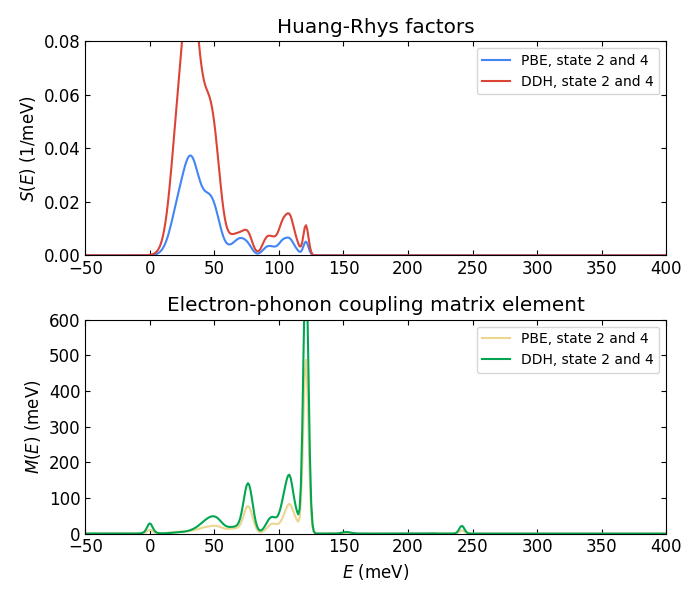

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6))

colors = [blue, red, goldenrod_yellow, emerald_green]

ax[0].plot(
    spectral_density_hrf_24_pbe[0], 
    spectral_density_hrf_24_pbe[1], 
    color=colors[0], 
    linestyle='-', 
    label=r'PBE, state 2 and 4'
)

ax[0].plot(
    spectral_density_hrf_24_ddh[0], 
    spectral_density_hrf_24_ddh[1], 
    color=colors[1], 
    linestyle='-', 
    label=r'DDH, state 2 and 4'
)

ax[1].plot(
    spectral_density_dH_dq_24_pbe[0],
    spectral_density_dH_dq_24_pbe[1],
    color=colors[2],
    label=r'PBE, state 2 and 4'
)

ax[1].plot(
    spectral_density_dH_dq_24_ddh[0],
    spectral_density_dH_dq_24_ddh[1],
    color=colors[3],
    label=r'DDH, state 2 and 4'
)

ax[0].set_title('Huang-Rhys factors')
ax[1].set_title('Electron-phonon coupling matrix element')

for i in range(2):
    ax[i].legend(loc='upper right', fontsize=10)
    ax[1].set_xlabel('$E$ (meV)')
    ax[0].set_ylabel('$S(E)$ (1/meV)')
    ax[1].set_ylabel('$M(E)$ (meV)')
    ax[i].tick_params(direction='in')
    ax[i].yaxis.set_ticks_position('both')
    ax[i].xaxis.set_ticks_position('both')
    ax[0].set_ylim([0, 0.08])
    ax[1].set_ylim([0, 600])
    ax[i].set_xlim([-50, 400])

fig.tight_layout()
plt.show()

In [16]:
print(sum(dict_nonrad_24_pbe['hr_factors']))
indices = np.argsort(dict_nonrad_24_pbe['hr_factors'])
print('index     freq (meV)      hr_factor     1-2hr_factor')
for ind in indices[-1:-11:-1]:
    print('%4d    % 12.6f    % 10.6f    % 10.6f' % (
        ind, dict_nonrad_24_pbe['freqs'][ind] * hbar / eV * 1e3,
        dict_nonrad_24_pbe['hr_factors'][ind],
        1 - 2 * dict_nonrad_24_pbe['hr_factors'][ind]
        ))


1.3208433127902024
index     freq (meV)      hr_factor     1-2hr_factor
  56       29.623925      0.064971      0.870058
  63       30.837392      0.049158      0.901684
  26       23.848125      0.045904      0.908191
   9       19.246007      0.032948      0.934104
  57       29.623925      0.027004      0.945991
   7       18.734097      0.026741      0.946517
  76       31.903302      0.024473      0.951055
  45       26.299544      0.022866      0.954268
 103       33.785475      0.020569      0.958862
  64       30.837392      0.020430      0.959141


In [17]:
print(sum(dict_nonrad_24_ddh['hr_factors']))
indices = np.argsort(dict_nonrad_24_ddh['hr_factors'])
print('index     freq (meV)      hr_factor     1-2hr_factor')
for ind in indices[-1:-11:-1]:
    print('%4d    % 12.6f    % 10.6f    % 10.6f' % (
        ind, dict_nonrad_24_ddh['freqs'][ind] * hbar / eV * 1e3,
        dict_nonrad_24_ddh['hr_factors'][ind],
        1 - 2 * dict_nonrad_24_ddh['hr_factors'][ind]
        ))


3.384116457532961
index     freq (meV)      hr_factor     1-2hr_factor
  56       29.623925      0.134172      0.731657
  57       29.623925      0.122823      0.754355
  63       30.837392      0.100444      0.799113
  26       23.848125      0.096079      0.807843
  64       30.837392      0.092149      0.815702
  27       23.848125      0.087321      0.825359
   9       19.246007      0.064324      0.871353
  10       19.246007      0.058635      0.882729
   7       18.734097      0.056084      0.887831
   8       18.734097      0.050706      0.898588


It can be seen that the spectral density $M(E)$ computed between state 2, 4 and that between state 3, 4 are the same, and is dominated by a single peak at 120 meV, which is the localized vibrational mode around the VV center.

In [18]:
# check normalization
print(np.sum(spectral_density_dH_dq_24_pbe[1] * (spectral_density_dH_dq_24_pbe[0][1] - spectral_density_dH_dq_24_pbe[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(dict_nonrad_24_pbe['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_24_pbe['freqs'])))

1.3184714193976384e-40
1.3184714193976388e-40


In [19]:
# check normalization
print(np.sum(spectral_density_dH_dq_24_ddh[1] * (spectral_density_dH_dq_24_ddh[0][1] - spectral_density_dH_dq_24_ddh[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(dict_nonrad_24_ddh['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_24_ddh['freqs'])))

2.2616552286177635e-40
2.2616552286177635e-40


## 2. Compute nonradiative rate

We can compute the lineshape function for both the radiative and non-radiative transitions at different temperatures, with a broadening parameter provided for each temperature.

In [20]:
temperatures = np.array([0.0, 50, 100, 150, 200, 250, 300, 350, 400])
zpl_broadenings = np.ones_like(temperatures)*0.18 # meV

rad_lineshapes_pbe = []
nonrad_lineshapes_pbe = []

rad_lineshapes_ddh = []
nonrad_lineshapes_ddh = []

for temp, zpl_broadening in zip(temperatures, zpl_broadenings):
    tmp = nonrad_24_pbe.compute_lineshape_fft(
        dict_nonrad_24_pbe,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    rad_lineshapes_pbe.append(tmp)
    print()

    tmp = nonrad_24_pbe.compute_nonrad_lineshape_fft(
        dict_nonrad_24_pbe,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    nonrad_lineshapes_pbe.append(tmp)
    print()

    tmp = nonrad_24_ddh.compute_lineshape_fft(
        dict_nonrad_24_ddh,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    rad_lineshapes_ddh.append(tmp)
    print()

    tmp = nonrad_24_ddh.compute_nonrad_lineshape_fft(
        dict_nonrad_24_ddh,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    nonrad_lineshapes_ddh.append(tmp)
    print()

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15


/home/svillani/Programs/pypl/pypl/lineshape.py:193: RuntimeWarning: divide by zero encountered in divide
  self.ph_occ = 1 / (np.exp((self.hrf["freqs"] * constants.hbar) / (constants.Boltzmann * self.temp)) - 1)


Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981494

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15


/home/svillani/Programs/pypl/pypl/lineshape.py:328: RuntimeWarning: divide by zero encountered in divide
  self.ph_occ = 1 / (np.exp((self.hrf["freqs"] * constants.hbar) / (constants.Boltzmann * self.temp)) - 1)


Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 8.229251328572299e-19

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981517

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 1.4116141632693315e-18

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981495

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999

<>:53: SyntaxWarning: invalid escape sequence '\G'
<>:53: SyntaxWarning: invalid escape sequence '\G'
/tmp/ipykernel_846055/2082705297.py:53: SyntaxWarning: invalid escape sequence '\G'
  ax[1].set_ylabel('$\Gamma(E)$ (s$^{-1}$)')


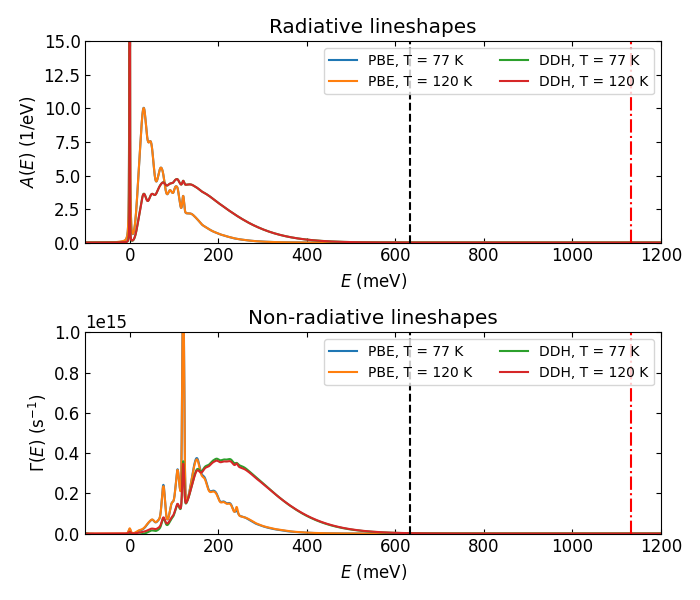

In [21]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6))

colors = [deep_violet, soft_coral, emerald_green]

temperatures_to_plot = np.array([77, 120])

for i, temp in enumerate(temperatures_to_plot):
    ax[0].plot(
        rad_lineshapes_pbe[i][0],
        rad_lineshapes_pbe[i][1],
        # color=colors[i],
        linestyle='-',
        label='PBE, T = %.0f K' % (temp)
    )
for i, temp in enumerate(temperatures_to_plot):
    ax[0].plot(
        rad_lineshapes_ddh[i][0],
        rad_lineshapes_ddh[i][1],
        # color=colors[i],
        linestyle='-',
        label='DDH, T = %.0f K' % (temp)
    )

for i, temp in enumerate(temperatures_to_plot):
    ax[1].plot(
        nonrad_lineshapes_pbe[i][0],
        nonrad_lineshapes_pbe[i][1] * 2 * np.pi / hbar,
        # color=colors[i],
        linestyle='-',
        label='PBE, T = %.0f K' % (temp)
    )
for i, temp in enumerate(temperatures_to_plot):
    ax[1].plot(
        nonrad_lineshapes_ddh[i][0],
        nonrad_lineshapes_ddh[i][1] * 2 * np.pi / hbar,
        # color=colors[i],
        linestyle='-',
        label='DDH, T = %.0f K' % (temp)
    )
    
ax[0].axvline(x=adiabatic_energy_1A1_1E_pbe, color='black', linestyle='--')
ax[1].axvline(x=adiabatic_energy_1A1_1E_pbe, color='black', linestyle='--')
ax[0].axvline(x=adiabatic_energy_1A1_1E_ddh, color='r', linestyle='-.')
ax[1].axvline(x=adiabatic_energy_1A1_1E_ddh, color='r', linestyle='-.')

ax[0].set_title('Radiative lineshapes')
ax[1].set_title('Non-radiative lineshapes')

for i in range(2):
    ax[i].legend(loc='upper right', ncols=2, fontsize=10)
    ax[i].set_xlabel('$E$ (meV)')
    ax[0].set_ylabel('$A(E)$ (1/eV)')
    ax[1].set_ylabel('$\Gamma(E)$ (s$^{-1}$)')
    ax[i].tick_params(direction='in')
    ax[i].yaxis.set_ticks_position('both')
    ax[i].xaxis.set_ticks_position('both')
    ax[0].set_ylim([0, 15])
    ax[1].set_ylim([0, 1e15])
    ax[i].set_xlim([-100, 1200])

fig.tight_layout()
plt.show()

We can compute the nonradiative rate at the corresponding nonadiabatic transition energy.

In [22]:
rate_non_rad_pbe = []
print('Nonradiative, all modes, PBE, singlets')
for i, temp in enumerate(temperatures):
    for energy, lineshape in zip(*nonrad_lineshapes_pbe[i]):
        if abs(energy - adiabatic_energy_1A1_1E_pbe) < 0.05:
            rate_non_rad_pbe.append(lineshape * 2 * np.pi / hbar)
            print('T = %3.f K, Energy = %.12e meV, rate = %.12e 1/s' % (
                temp, energy, lineshape * 2 * np.pi / hbar)
            )
print()

rate_non_rad_ddh = []
print('Nonradiative, all modes, DDH, singlets')
for i, temp in enumerate(temperatures):
    for energy, lineshape in zip(*nonrad_lineshapes_ddh[i]):
        if abs(energy - adiabatic_energy_1A1_1E_ddh) < 0.05:
            rate_non_rad_ddh.append(lineshape * 2 * np.pi / hbar)
            print('T = %3.f K, Energy = %.12e meV, rate = %.12e 1/s' % (
                temp, energy, lineshape * 2 * np.pi / hbar)
            )
print()

Nonradiative, all modes, PBE, singlets
T =   0 K, Energy = 6.329999999992e+02 meV, rate = 2.222846856369e+10 1/s
T =  50 K, Energy = 6.329999999992e+02 meV, rate = 2.520127948759e+10 1/s
T = 100 K, Energy = 6.329999999992e+02 meV, rate = 2.549923192327e+10 1/s
T = 150 K, Energy = 6.329999999992e+02 meV, rate = 2.636713298181e+10 1/s
T = 200 K, Energy = 6.329999999992e+02 meV, rate = 2.787774922424e+10 1/s
T = 250 K, Energy = 6.329999999992e+02 meV, rate = 3.011329563413e+10 1/s
T = 300 K, Energy = 6.329999999992e+02 meV, rate = 3.318766477297e+10 1/s
T = 350 K, Energy = 6.329999999992e+02 meV, rate = 3.723701159301e+10 1/s
T = 400 K, Energy = 6.329999999992e+02 meV, rate = 4.242316751998e+10 1/s

Nonradiative, all modes, DDH, singlets
T =   0 K, Energy = 1.131999999998e+03 meV, rate = 7.521412802283e+09 1/s
T =  50 K, Energy = 1.131999999998e+03 meV, rate = 7.535586509057e+09 1/s
T = 100 K, Energy = 1.131999999998e+03 meV, rate = 7.555465261430e+09 1/s
T = 150 K, Energy = 1.13199999999

<>:16: SyntaxWarning: invalid escape sequence '\G'
<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:16: SyntaxWarning: invalid escape sequence '\G'
<>:45: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_846055/2179203522.py:16: SyntaxWarning: invalid escape sequence '\G'
  ax[0].set_ylabel('$\Gamma_\mathrm{NR}$ (GHz)')
/tmp/ipykernel_846055/2179203522.py:45: SyntaxWarning: invalid escape sequence '\m'
  ax[2].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')


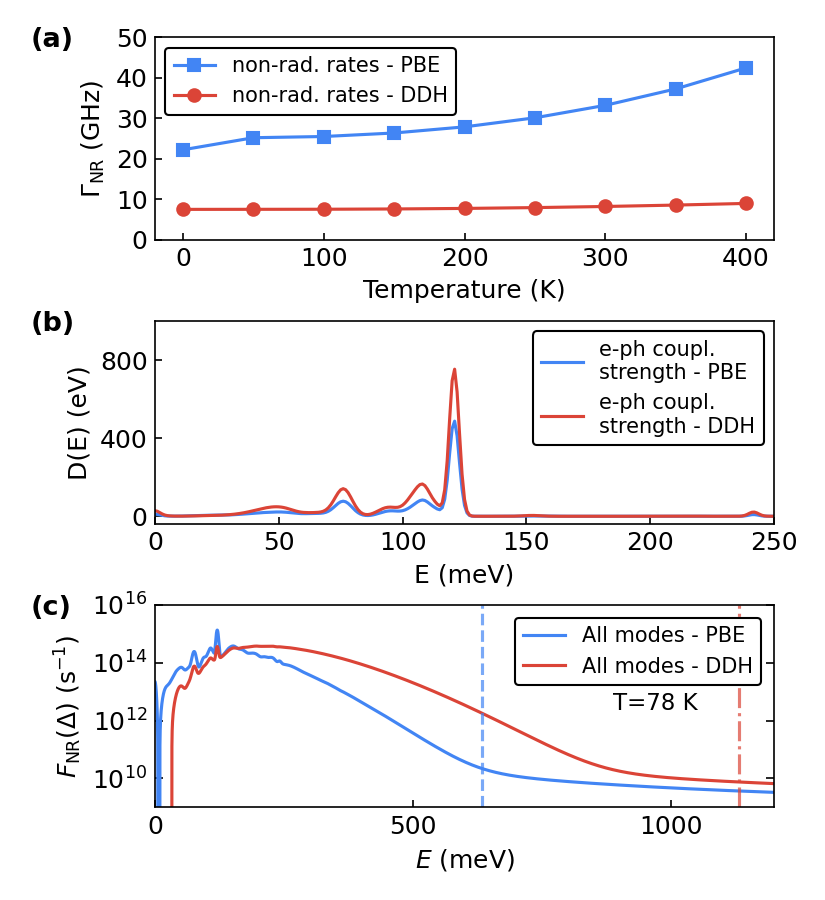

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# -----------------------------
rate_non_rad_pbe = np.array(rate_non_rad_pbe)
rate_non_rad_ddh = np.array(rate_non_rad_ddh)

# -----------------------------
fig, ax = plt.subplots(3, 1, figsize=(5.5, 6), dpi=150)
ax=ax.ravel()
#
ax[0].plot(temperatures, rate_non_rad_pbe*1e-9, c=blue, marker='s', label='non-rad. rates - PBE')
ax[0].plot(temperatures, rate_non_rad_ddh*1e-9, c=red, marker='o', label='non-rad. rates - DDH')
ax[0].set_xlabel('Temperature (K)')
ax[0].set_ylabel('$\Gamma_\mathrm{NR}$ (GHz)')
ax[0].set_ylim(ymin=0,ymax=50.0)
ax[0].tick_params(direction='in')
ax[0].set_yticks([0,10,20,30,40,50])
ax[0].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='upper left')
# 
ax[1].plot(spectral_density_dH_dq_24_pbe[0],spectral_density_dH_dq_24_pbe[1],
        color=blue,ls='-',label='e-ph coupl.\nstrength - PBE')
ax[1].plot(spectral_density_dH_dq_24_ddh[0],spectral_density_dH_dq_24_ddh[1],
        color=red,ls='-',label='e-ph coupl.\nstrength - DDH')
ax[1].set_xlabel('E (meV)')
ax[1].set_ylabel('D(E) (eV)')
ax[1].tick_params(direction='in')
ax[1].set_yticks([0,400,800])
ax[1].set_xlim([0, 250])
ax[1].set_ylim(ymax=1000)
ax[1].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='upper right')
#
ax[2].plot(nonrad_lineshapes_pbe[0][0], nonrad_lineshapes_pbe[0][1]*2*np.pi/hbar, color=blue, linestyle='-',label='All modes - PBE')
ax[2].plot(nonrad_lineshapes_ddh[0][0], nonrad_lineshapes_ddh[0][1]*2*np.pi/hbar, color=red, linestyle='-',label='All modes - DDH')
ax[2].set_yscale('log')
ax[2].set_ylim(bottom=1e9, top=1e16)
ax[2].yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))
ax[2].tick_params(axis='y', which='major', direction='in', length=4, right=True)
ax[2].tick_params(axis='y', which='minor', direction='in', length=2, right=True)
ax[2].tick_params(axis='x', which='major', direction='in', top=False)
ax[2].yaxis.set_ticks_position('both')
ax[2].set_yticks([1e10, 1e12, 1e14, 1e16])
ax[2].set_xlabel('$E$ (meV)')
ax[2].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')
ax[2].tick_params(axis='x', which='both', direction='in')
ax[2].text(0.74, 0.57, 'T=78 K', transform=ax[2].transAxes, ha='left', va='top', fontsize=11)
ax[2].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='center', bbox_to_anchor=(0.78,0.77))
ax[2].set_xlim([-0, 1200])
ax[2].set_xticks([0, 500, 1000])
ax[2].axvline(x=adiabatic_energy_1A1_1E_pbe, color=blue, alpha=0.7, linestyle='--')
ax[2].axvline(x=adiabatic_energy_1A1_1E_ddh, color=red, alpha=0.7, linestyle='-.')
#
labels = ['(a)', '(b)', '(c)'] 
for i, label in enumerate(labels):
    ax[i].text(
        -0.2, 1.05, label,
        transform=ax[i].transAxes,
        ha='left', va='top',
        fontsize=13, fontweight='bold'
    )

fig.tight_layout()
fig.subplots_adjust(hspace=0.4)
plt.show()